# Spaceship Titanic: Ensemble Classification Methods

## Comparing Bagging, Pasting, Random Forest, Gradient Boosting and AdaBoost

This notebook predicts whether a passenger was **Transported** using demographic, travel, cabin and spending information. It compares five ensemble classification approaches under the same preprocessing conditions.


## 1. Analytical objective

The target **Transported** is Boolean (True/False), so this is a binary classification problem.

The models are evaluated primarily with:

- **Accuracy:** the proportion of all predictions that are correct.  
- **Precision:** among passengers predicted as transported, the proportion actually transported.  
- **Recall:** among passengers actually transported, the proportion correctly identified.  
- **F1 score:** the harmonic mean of precision and recall.

**R² is not used** because it is a regression metric intended for continuous numerical targets.


## 2. Import libraries and load the data

**The data is loaded from the course repository, and "random_state=42" is used throughout to ensure the results are reproducible.**



In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


In [2]:
DATA_URL = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/spaceship_titanic.csv"

spaceship = pd.read_csv(DATA_URL)

print("Dataset shape:", spaceship.shape)
display(spaceship.head())


Dataset shape: (8693, 14)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


## 3. Initial data-quality assessment


In [3]:
print("Column data types:")
display(spaceship.dtypes.to_frame("dtype"))

quality_summary = pd.DataFrame({
    "missing_values": spaceship.isna().sum(),
    "missing_percentage": (spaceship.isna().mean() * 100).round(2),
    "unique_values": spaceship.nunique(dropna=False),
})

print("Missing-value and uniqueness summary:")
display(quality_summary)
print("Duplicate rows:", spaceship.duplicated().sum())
print("\nTarget distribution:")
display(spaceship["Transported"].value_counts(dropna=False).to_frame("count"))


Column data types:


,dtype
PassengerId,object
HomePlanet,object
CryoSleep,object
Cabin,object
Destination,object
Age,float64
VIP,object
RoomService,float64
FoodCourt,float64
ShoppingMall,float64


Missing-value and uniqueness summary:


,missing_values,missing_percentage,unique_values
PassengerId,0,0.00,8693
HomePlanet,201,2.31,4
CryoSleep,217,2.50,3
Cabin,199,2.29,6561
Destination,182,2.09,4
Age,179,2.06,81
VIP,203,2.34,3
RoomService,181,2.08,1274
FoodCourt,183,2.11,1508
ShoppingMall,208,2.39,1116


Duplicate rows: 0

Target distribution:


,count
Transported,
True,4378
False,4315


## 4. Feature engineering

The following features are created before modelling:

"GroupId:" the group identifier extracted from PassengerId.  
"GroupSize": number of passengers sharing the same group identifier.  
"Deck and Side": extracted from Cabin; the cabin number is omitted to avoid excessive categories.  
"TotalSpend": total expenditure across the five service columns.  
"NoSpending": whether total recorded expenditure equals zero.  
PassengerId, Cabin and Name are removed after extracting useful information. These identifiers are not meaningful measurements and could encourage memorisation.


In [4]:
spaceship_model = spaceship.copy()

spend_columns = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

spaceship_model["GroupId"] = spaceship_model["PassengerId"].str.split("_").str[0]
spaceship_model["GroupSize"] = (
    spaceship_model.groupby("GroupId")["PassengerId"].transform("size")
)

cabin_parts = spaceship_model["Cabin"].str.split("/", expand=True)
spaceship_model["Deck"] = cabin_parts[0]
spaceship_model["Side"] = cabin_parts[2]

spaceship_model["TotalSpend"] = spaceship_model[spend_columns].sum(
    axis=1, min_count=1
)
spaceship_model["NoSpending"] = spaceship_model["TotalSpend"].eq(0)

spaceship_model = spaceship_model.drop(
    columns=["PassengerId", "GroupId", "Cabin", "Name"]
)

print("Modelling dataset shape:", spaceship_model.shape)
display(spaceship_model.head())


Modelling dataset shape: (8693, 16)


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,GroupSize,Deck,Side,TotalSpend,NoSpending
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,1,B,P,0.0,True
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,1,F,S,736.0,False
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,2,A,S,10383.0,False
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,2,A,S,5176.0,False
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True,1,F,S,1091.0,False


## 5. Define features and target

The target is encoded as "1" for transported and "0" for not transported. Missing target values, if any, are excluded because supervised learning requires known labels.


In [5]:
spaceship_model = spaceship_model.dropna(subset=["Transported"]).copy()

X = spaceship_model.drop(columns="Transported")
y = spaceship_model["Transported"].astype(int)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nClass proportions:")
display(y.value_counts(normalize=True).sort_index().rename("proportion").to_frame())


Feature matrix shape: (8693, 15)
Target shape: (8693,)

Class proportions:


,proportion
Transported,
0,0.496376
1,0.503624


## 6. Stratified train–test split

The 80/20 split is stratified so both datasets retain approximately the same class proportions. The test set remains unseen during training.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

split_balance = pd.DataFrame({
    "training": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
})
display(split_balance)


X_train shape: (6954, 15)
X_test shape: (1739, 15)
y_train shape: (6954,)
y_test shape: (1739,)


,training,test
Transported,,
0,0.496405,0.496262
1,0.503595,0.503738


## 7. Leakage-safe preprocessing

Preprocessing is placed inside a scikit-learn "Pipeline". Consequently, imputation, scaling and one-hot encoding are fitted using only the training data during ".fit()".

- Numerical missing values: median imputation.
- Numerical scaling: standardization.
- Categorical missing values: most-frequent imputation.
- Categorical encoding: one-hot encoding with unknown test categories safely ignored.

Tree models do not normally require scaling, but the same preprocessing is retained to ensure a fair and consistent comparison with the previous lab.


In [7]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
preprocessor


Numerical features: ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'GroupSize', 'TotalSpend']
Categorical features: ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'Side', 'NoSpending']


,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## 8. Model definitions

- **Bagging** trains multiple decision trees on samples drawn **with replacement** ("bootstrap=True") and combines their predictions.
- **Pasting** trains multiple decision trees on samples drawn **without replacement** ("bootstrap=False") and combines their predictions.
- **Random Forest** adds random feature selection to bagging, reducing correlation among trees.
- **Gradient Boosting** builds trees sequentially, with each tree correcting previous errors.
- **AdaBoost** increases attention on observations that previous weak learners classified incorrectly.


In [8]:
models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=8, random_state=42),
        n_estimators=100,
        bootstrap=True,
        random_state=42,
        n_jobs=-1,
    ),
    "Pasting": BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=8, random_state=42),
        n_estimators=100,
        bootstrap=False,
        random_state=42,
        n_jobs=-1,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=150,
        learning_rate=0.05,
        random_state=42,
    ),
}

models


{'Bagging': BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=8,
                                                    random_state=42),
                   n_estimators=100, n_jobs=-1, random_state=42),
 'Pasting': BaggingClassifier(bootstrap=False,
                   estimator=DecisionTreeClassifier(max_depth=8,
                                                    random_state=42),
                   n_estimators=100, n_jobs=-1, random_state=42),
 'Random Forest': RandomForestClassifier(min_samples_leaf=2, n_estimators=250, n_jobs=-1,
                        random_state=42),
 'Gradient Boosting': GradientBoostingClassifier(learning_rate=0.05, n_estimators=150,
                            random_state=42),
 'AdaBoost': AdaBoostClassifier(learning_rate=0.05, n_estimators=150, random_state=42)}

## 9. Train and evaluate all ensemble models


In [9]:
results = []
fitted_models = {}
test_predictions = {}

for model_name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier),
    ])

    pipeline.fit(X_train, y_train)
    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)

    fitted_models[model_name] = pipeline
    test_predictions[model_name] = y_test_pred

    results.append({
        "Model": model_name,
        "Training Accuracy": accuracy_score(y_train, y_train_pred),
        "Test Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_test_pred, zero_division=0),
    })

results_df = pd.DataFrame(results)
results_df["Generalization Gap"] = (
    results_df["Training Accuracy"] - results_df["Test Accuracy"]
)
results_df = results_df.sort_values(
    ["F1 Score", "Test Accuracy"], ascending=False
).reset_index(drop=True)

results_display = results_df.copy()
metric_columns = [
    "Training Accuracy", "Test Accuracy", "Precision",
    "Recall", "F1 Score", "Generalization Gap"
]
results_display[metric_columns] = results_display[metric_columns].round(4)
display(results_display)


,Model,Training Accuracy,Test Accuracy,Precision,Recall,F1 Score,Generalization Gap
0,Gradient Boosting,0.8109,0.8028,0.7925,0.8242,0.8081,0.0081
1,Bagging,0.8471,0.8045,0.7998,0.8162,0.8079,0.0427
2,Random Forest,0.9167,0.8085,0.8244,0.7877,0.8056,0.1082
3,Pasting,0.8303,0.7901,0.7768,0.8185,0.7971,0.0402
4,AdaBoost,0.7565,0.7499,0.7984,0.6735,0.7307,0.0067


## 10. Visual comparison


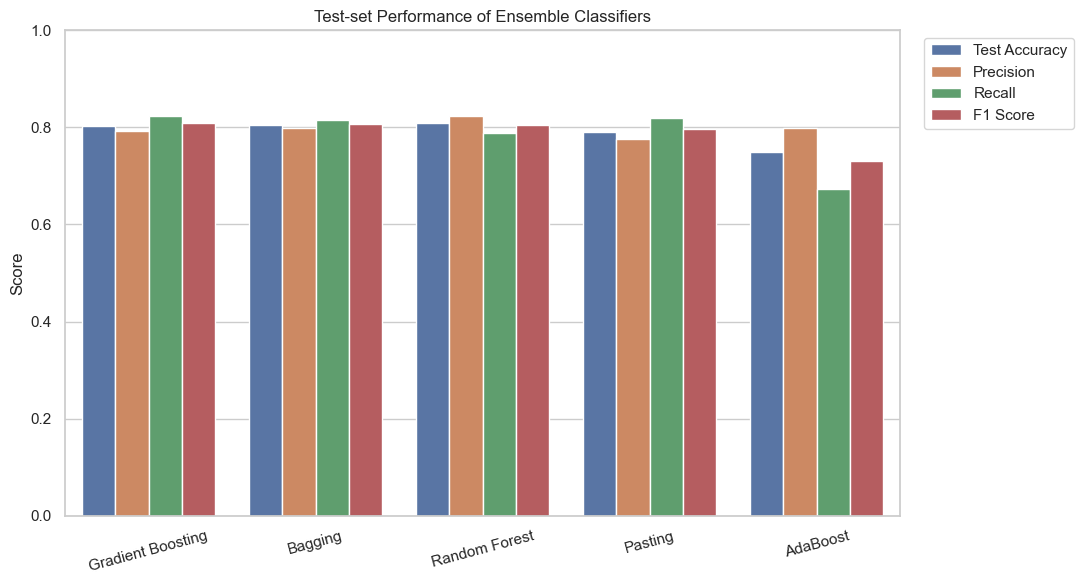

In [10]:
plot_data = results_df.melt(
    id_vars="Model",
    value_vars=["Test Accuracy", "Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score",
)

plt.figure(figsize=(11, 6))
sns.barplot(data=plot_data, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1)
plt.title("Test-set Performance of Ensemble Classifiers")
plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 11. Confusion matrices


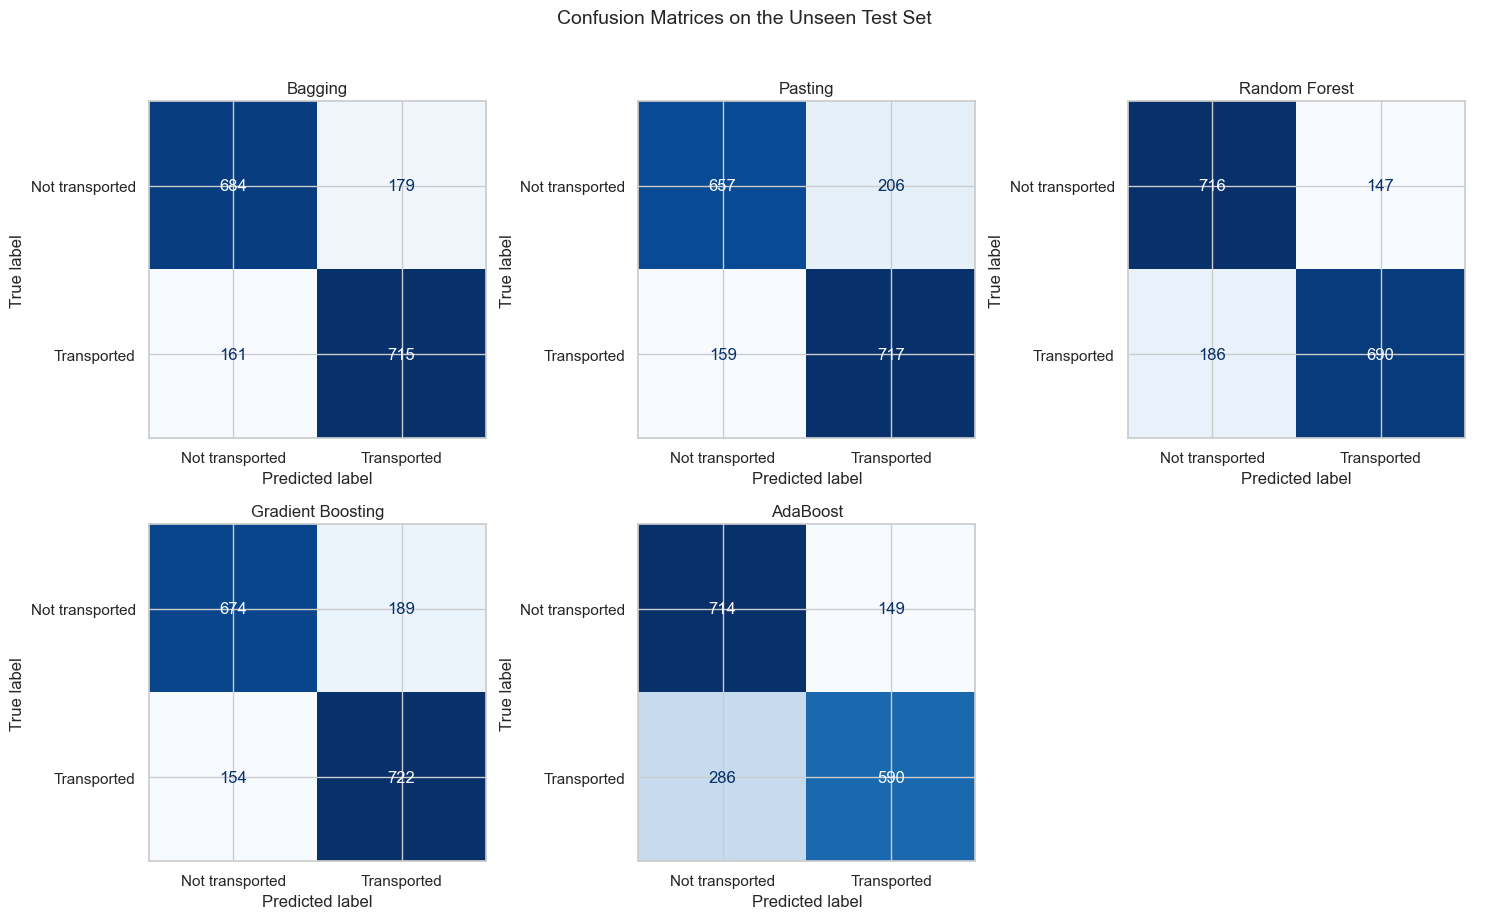

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, model_name in zip(axes.ravel(), models.keys()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_predictions[model_name],
        display_labels=["Not transported", "Transported"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(model_name)

for ax in axes.ravel()[len(models):]:
    ax.axis("off")

plt.suptitle("Confusion Matrices on the Unseen Test Set", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


## 12. Detailed report for the selected model


In [12]:
best_model_name = results_df.loc[0, "Model"]
best_predictions = test_predictions[best_model_name]

print("Selected model:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["Not transported", "Transported"],
    digits=3,
))


Selected model: Gradient Boosting

Classification report:
                 precision    recall  f1-score   support

Not transported      0.814     0.781     0.797       863
    Transported      0.793     0.824     0.808       876

       accuracy                          0.803      1739
      macro avg      0.803     0.803     0.803      1739
   weighted avg      0.803     0.803     0.803      1739



## 13. Conclusion

The best model is selected programmatically using the highest **test F1 score**, with test accuracy used as a tie-breaker. This is more reliable than hard-coding a winner because exact results can vary slightly across software versions.

F1 is appropriate because this is a classification task and it balances precision with recall. The generalization gap should also be considered: a very high training score combined with a noticeably lower test score can indicate overfitting.

The final comparison is fair because all four classifiers use:

- the same engineered features;
- the same stratified train/test split;
- the same leakage-safe preprocessing; and
- the same unseen test observations.

Bagging and Pasting are both evaluated explicitly. Bagging samples training
observations with replacement, whereas Pasting samples them without replacement.

The selected result demonstrates which ensemble method offers the strongest balance between identifying transported passengers and avoiding incorrect positive predictions on this dataset.
